In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)

In [2]:
df = pd.read_csv("diabetes_prediction_dataset.csv")
# Display first five rows
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [4]:
print(df.shape)

(100000, 9)


In [5]:
print(df.isnull().sum())

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


In [6]:
print(df['diabetes'].unique())
print(df['diabetes'].value_counts())

[0 1]
diabetes
0    91500
1     8500
Name: count, dtype: int64


In [7]:
X = df[['gender', 'age', 'hypertension', 'heart_disease',
        'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level']]


y = df['diabetes']


X.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level
0,Female,80.0,0,1,never,25.19,6.6,140
1,Female,54.0,0,0,No Info,27.32,6.6,80
2,Male,28.0,0,0,never,27.32,5.7,158
3,Female,36.0,0,0,current,23.45,5.0,155
4,Male,76.0,1,1,current,20.14,4.8,155


In [8]:
X = pd.get_dummies(X, columns=['gender', 'smoking_history'], drop_first=True, dtype=int)
X.head()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Male,gender_Other,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,80.0,0,1,25.19,6.6,140,0,0,0,0,0,1,0
1,54.0,0,0,27.32,6.6,80,0,0,0,0,0,0,0
2,28.0,0,0,27.32,5.7,158,1,0,0,0,0,1,0
3,36.0,0,0,23.45,5.0,155,0,0,1,0,0,0,0
4,76.0,1,1,20.14,4.8,155,1,0,1,0,0,0,0


In [9]:
print(y.head())
print(y.value_counts())

0    0
1    0
2    0
3    0
4    0
Name: diabetes, dtype: int64
diabetes
0    91500
1     8500
Name: count, dtype: int64


In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# Display dataset shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (80000, 13)
X_test shape: (20000, 13)
y_train shape: (80000,)
y_test shape: (20000,)


In [11]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)
print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [12]:
y_pred = model.predict(X_test)


comparison = pd.DataFrame({
    'Actual Diabetes': y_test.values,
    'Predicted Diabetes': y_pred
})


comparison.head(10)

,Actual Diabetes,Predicted Diabetes
0,0,0
1,0,0
2,0,0
3,0,0
4,1,0
5,0,0
6,0,0
7,0,0
8,0,0
9,0,0


In [13]:
accuracy = accuracy_score(y_test, y_pred)

cm = confusion_matrix(y_test, y_pred)


report = classification_report(
    y_test,
    y_pred,
    target_names=['No Diabetes', 'Diabetes']
)

print("Accuracy:", accuracy)
print("\nConfusion Matrix:\n", cm)
print("\nClassification Report:\n", report)

Accuracy: 0.9592

Confusion Matrix:
 [[18129   163]
 [  653  1055]]

Classification Report:
               precision    recall  f1-score   support

 No Diabetes       0.97      0.99      0.98     18292
    Diabetes       0.87      0.62      0.72      1708

    accuracy                           0.96     20000
   macro avg       0.92      0.80      0.85     20000
weighted avg       0.96      0.96      0.96     20000



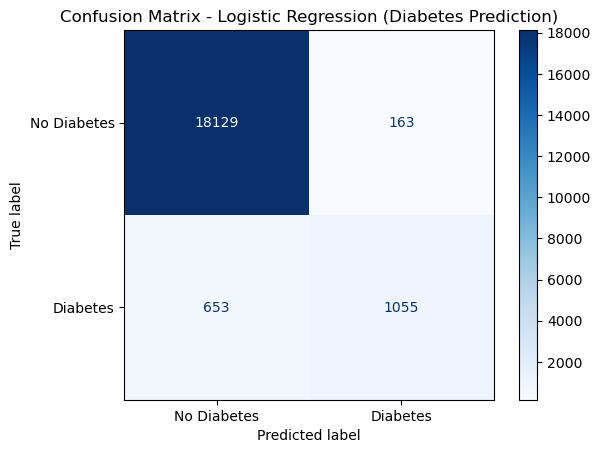

In [14]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Diabetes', 'Diabetes']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression (Diabetes Prediction)')
plt.show()

### Conclusion

Logistic Regression was used to predict whether a person has diabetes (1) or not (0) based on features such as age, BMI, HbA1c level, blood glucose level, hypertension, heart disease, gender, and smoking history.

The dataset is highly imbalanced (~91.5% non-diabetic vs ~8.5% diabetic). Logistic Regression typically achieves high overall accuracy (around 95-96%) on this dataset because of the majority class, but recall for the minority class (Diabetes) is usually lower.

This model serves as a solid baseline. Further improvements can be obtained by handling class imbalance (e.g., class_weight='balanced'), feature scaling, or trying more advanced classifiers.